<a href="https://colab.research.google.com/github/ashsiendo/DATA-201-Labs/blob/main/Assignments/Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 8 Homework** - Ash Ibasan
We'll use the `Hitters` dataset from the lab in week 8 to see how changing the regularization strength (`α`) affects Lasso regression models, and look at training and test RMSE, how many predictors are kept, and how easy the model is to interpret.

The objective is to compare the results and consider when it makes sense to use ordinary linear regression, Ridge, or Lasso in different modeling scenarios.

> **Note to self: Comments throughout are used as guides, mainly for Python syntax, reasons why certain steps are used, and understanding and interpreting the results.**

## Setup - Data Preparation and Preprocessing

*We're going to be predicting professional baseball players' salaries using Lasso regression, and we'll utilize the following: prep the `Hitters` dataset, training/test split, and preprocessing steps*

In [17]:
%pip -q install ISLP

In [18]:
# import relevant libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error

In [19]:
# load Hitters dataset
hitters = load_data('Hitters')
hitters = hitters.dropna(subset=['Salary']).copy() # remove rows with missing salary values

# define predictors (X); response variable (y)
X = hitters.drop(columns='Salary')
y = hitters['Salary']  # salary in thousands of dollars

# identify numerical and categorical predictors
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split( # training/test split
    X, y, test_size=0.25, random_state=12
)

print('Total observations:', len(X))
print('Training observations:', len(X_train))
print('Test observations:', len(X_test))
print('Categorical predictors are', cat_cols)

Total observations: 263
Training observations: 197
Test observations: 66
Categorical predictors are ['League', 'Division', 'NewLeague']


***Note to self:*** `Salary` is a continuous numeric response, so the problem is regression rather than classification. We'll be using RMSE to measure our prediction error rather than some classification metrics e.g., accuracy, precision, or recall

- `dropna(subset=['Salary'])` removes rows where the `Salary` value (response variable) is missing. Using `.copy()` makes a new `DataFrame` with the remaining data.

- `X` contains the predictor variables, and `y` is the response variable (`Salary`). We take `Salary` out of `X`, so we don't use the outcome as a predictor

- `select_dtypes()` splits numerical and categorical predictors so we can preprocess them in different ways

- `test_size=0.25` sets aside 25% of the data for testing, and `random_state=12` makes sure the split is the same each time we run the code


We train the models using the training data. The test data then helps us see how well the models predict salaries for new cases.

In [20]:
def make_preprocessor(): # preprocessing function
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(
                handle_unknown='ignore',
                drop='first'
            ), cat_cols)
        ]
    )

**Note to self:** Lasso penalizes coefficient sizes, so it's important to standardize numerical predictors. This way, we reduce the effect of differences in numerical predictor scales on regularization

- `StandardScaler()` is used to standardize numerical predictors
- `OneHotEncoder()` turns categorical variables into numerical indicator columns, so no artificial order is assigned
- Setting `drop='first'` removes one category from each categorical predictor to avoid redundant indicator columns
- The encoder can process categories in the test data that did not appear during training with `handle_unknown='ignore'`
- `ColumnTransformer` applies the right preprocessing steps to each group of predictors

Putting this preprocessor in a `Pipeline` makes sure that scaling and encoding are fitted only on the training data (not test data)



## Part 1 - Experiment with α

*We'll use the `Hitters` dataset and the same training/test split for all three Lasso models, each with a different regularization strength: `alpha = 0.1, 10, and 100`, and for each model, let's compare training and test RMSE and also the number of nonzero coefficients (retained predictors). The goal is to find out how changing `alpha` affects the model complexity level and prediction performance*

*In Lasso (L1), increasing `alpha` makes regularization stronger, shrinking coefficients toward zero and removing predictors, but having fewer predictors does not always mean the model will perform better on new data*

In [21]:
alpha_values = [0.1, 10, 100]
rows = []

for a in alpha_values:
    pipe = Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', Lasso(alpha=a, max_iter=30000))
    ])

    pipe.fit(X_train, y_train)

    # calc training, test prediction errors
    train_rmse = np.sqrt(mean_squared_error(y_train, pipe.predict(X_train)))
    test_rmse = np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))

    # count coefficients that Lasso retains
    coefs = pipe.named_steps['model'].coef_
    nonzero = int(np.sum(np.abs(coefs) > 1e-6))

    # add each model's results to the table
    rows.append({
        'Alpha': a,
        'Training RMSE': train_rmse,
        'Test RMSE': test_rmse,
        'Nonzero coefficients': nonzero
    })

table_alpha = pd.DataFrame(rows)
display(table_alpha.round(2))

,Alpha,Training RMSE,Test RMSE,Nonzero coefficients
0,0.1,313.25,297.85,19
1,10.0,337.66,273.74,10
2,100.0,376.91,310.59,5


***Note to self:*** The `for` loop goes through each `alpha` value, fits a Lasso model, calculates the training and test RMSE, and counts how many coefficients are not zero each time. It then adds the results as `rows` (`append()`) and after the loop finishes, the results are converted into a `DataFrame` to compare all three models

**As α increases, what happens to the number of retained predictors?**

> The Lasso predictor numbers go down as `α` increases. At `alpha = 0.1`, it keeps 19 non-zero coefficients; at `alpha = 10`, it drops to 10; and at `alpha = 100`, it keeps only 5. That's because stronger regularization shrinks more coefficients to zero

**Does a smaller number of predictors always lead to a lower test RMSE?**

> Having fewer predictors does not always mean a lower test RMSE. At `alpha = 10`, the model has 10 coefficients and the lowest test RMSE (273.74). At `alpha = 100`, with only 5 coefficients, the test RMSE is higher (310.59). Removing too many predictors can hurt performance because useful information might be lost

## Part 2 - Visualize and Interpret
*We'll show how the three regularization strengths affect test RMSE using Part 1's results*

*We should see how changing `alpha` impacts prediction performance and interpret the results in terms of the bias-variance trade-off*

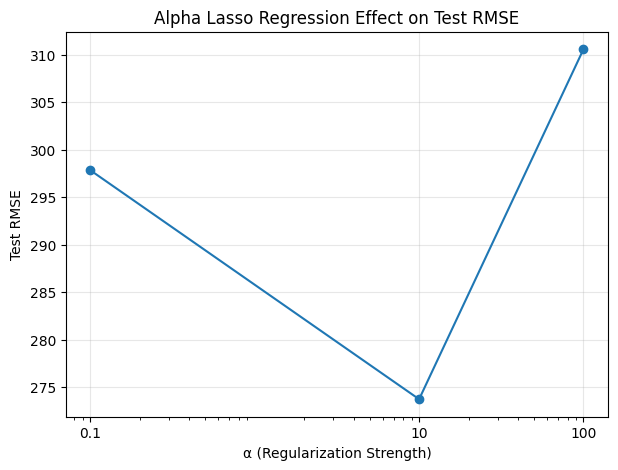

In [22]:
# plot test RMSE for each α value
plt.figure(figsize=(7, 5))

plt.plot(
    table_alpha['Alpha'],
    table_alpha['Test RMSE'],
    marker='o'
)

plt.xscale('log')  # show widely spaced α values on logarithmic scale
plt.xticks([0.1, 10, 100], ['0.1', '10', '100'])

plt.xlabel('α (Regularization Strength)')
plt.ylabel('Test RMSE')
plt.title('Alpha Lasso Regression Effect on Test RMSE')
plt.grid(True, alpha=0.3)

plt.show()

***Note to self:*** Regularization involves a bias–variance trade-off. Increasing `alpha` can  make the model simpler (reduce model complexity) and lower variance, but excessive regularization can increase bias and lead to underfitting

Training RMSE increased as `alpha` increased, while test RMSE decreased, then increased. The model with `alpha = 10` had the lowest test RMSE (even though it had a higher training RMSE than the `alpha = 0.1` model), so a model that fits the training data better`doesn't necessarily predict new data better

**Which α produces the lowest test RMSE?**
> `alpha = 10` gives the lowest test RMSE (273.74) among the three models, meaning it performed best at predicting salaries on the test data for this split

**Which α appears to cause the most underfitting? Explain using bias.**

> `alpha = 100` appears to be the most underfitted, as it's using the most regularization and only has 5 non-zero coefficients. It also has the highest training RMSE (376.91), suggesting it's too limited to pick up on some of the relationships in the data; that is a clear demonstration of the effect of too much regularization leading to high bias

**Why might a model with higher training RMSE produce lower test RMSE?**
> A model can have a higher training RMSE than another (it fits the training data worse) but still have a lower test RMSE; the main idea behind regularization is to help prevent overfitting. For example, at `alpha = 10`, the training RMSE is higher (337.66) than at `alpha = 0.1` (313.25), but the test RMSE is lower (273.74 vs 297.85). Regularization can help a model perform better on new data even if the training error goes up

## Part 3 - Interpret the Model

*Let's review the Lasso model with `alpha = 100` from Part 1 to find out which predictors were removed by regularization*

*We want to see what zero coefficients mean and how having fewer predictors changes how we interpret the model*


In [23]:
# fit Lasso using alpha = 100
pipe_100 = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', Lasso(alpha=100, max_iter=30000))
])

pipe_100.fit(X_train, y_train)

# get feature names and fitted coefficients
feature_names = pipe_100.named_steps['preprocess'].get_feature_names_out()
coefs = pipe_100.named_steps['model'].coef_

# create table showing each feature's coefficient
coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefs
})

# identify coefficients treated as zero
zero_coefs = coef_table.loc[np.abs(coef_table['Coefficient']) <= 1e-6]
display(zero_coefs.round(4))

,Feature,Coefficient
0,num__AtBat,0.0
2,num__HmRun,0.0
3,num__Runs,0.0
4,num__RBI,0.0
6,num__Years,0.0
7,num__CAtBat,0.0
8,num__CHits,0.0
9,num__CHmRun,0.0
12,num__CWalks,0.0
14,num__Assists,0.0


***Note to self:*** `.coef_` gives the coefficients from the fitted Lasso model, and `get_feature_names_out()` lists the feature names after preprocessing.

If `.loc[]` is used with `np.abs(...) <= 1e-6`, it will filter the table down to just the coefficients that are zero or almost zero.

When `alpha = 100`, Lasso sets 14 coefficients to zero and keeps 5 non-zero, matching what we saw in Part 1; the model doesn't use those 14 features to predict salary, but that doesn't mean those features have no connection to salary.

**Identify two predictors that Lasso sets to zero at α = 100.**

> At `alpha = 100`, Lasso sets the coefficients for `AtBat` (times at bat) and `HmRun` (home runs) to zero. Both show up as zero in the coefficient table

**Does setting their coefficients to zero prove these predictors have no relationship with salary? Explain.**
> A zero coefficient doesn't prove that those predictors have nothing to do with salary. All it means is that the Lasso model isn't using them to make its predictions. They could well be related to salary, particularly if the other predictors in the model already capture that information

**If two models have very similar test RMSE but one uses fewer predictors, which would you prefer? Explain in terms of interpretability and predictive performance.**
> If two models have similar test RMSE, I would choose the one with fewer predictors because it's easier to understand and interpret while delivering nearly the same predictive performance. I would also check if the difference in test RMSE is important for the problem

## Part 4 - Right Regression Model Choices

*I'll pick a regression model based on
the dataset and the goal of the analysis for each scenario. Then, I will explain why
the model is a good fit*

> ***Choices:*** Ridge (L2), Lasso (L1), ordinary linear regression, or not sure

> ***Note to self:*** The blockquotes (>) in this part highlight the important clues from each scenario, while the `Think:` questions are self-hints to help me decide which model would fit best

**Reminder:** *"There is not always enough information to determine which model will perform best.
Consider when cross-validation would be necessary to make a decision."*

### **Scenario A**

A researcher has data from 80 patients with 200 medical measurements. The
goal is to identify a small number of measurements that may be useful for predicting
disease severity.

> 80 patients, 200 medical measurements - the researcher wants to narrow them down to a small set of useful measurements for predicting disease severity.

*Think: Which model can reduce the number of predictors by setting some coefficients to zero?*

1.  **Lasso** - the researcher needs to narrow down a large number of predictors, such as 200 measurements here. It works by shrinking some of the coefficients all the way to zero, which then removes those predictors from the model, resulting in a much simpler model.



### **Scenario B**

A company wants to predict employee salaries using 40 predictors. Many
predictors are strongly correlated, and the company believes most contain useful
information. Keeping all predictors is not a concern.

> The company believes most predictors contain useful information and doesn't mind keeping them all. 40 predictors, many strongly correlated. The company believes most are useful and wants to keep them.

*Think: Which regularization method handles correlated predictors while generally retaining them?*

2.   **Ridge** - many of the predictors are highly correlated, yet the company still wants to keep them. Ridge will shrink the coefficients down to reduce their impact, without removing the predictors altogether.


### **Scenario C**

A researcher has 10,000 observations and only three predictors. The
relationship appears approximately linear, and the researcher wants a simple model that is
easy to interpret.

> 10,000 observations and only 3 predictors - the relationship seems approximately linear, and the researcher wants a simple model that's easy to interpret.

*Think: Do we necessarily need a regularization penalty for a relatively simple model?*

3. **Ordinary linear regression** - it works well when we've got just a few predictors (in our case, 3), and the relationship is fairly linear. In that simple scenario, regularization may be unnecessary unless it demonstrably improves performance.



### **Scenario D**
A company has 500 observations and 25 predictors. It is unclear how many
predictors are useful or how strongly they are correlated. The company wants the most
accurate predictions possible.

> 500 observations and 25 predictors - we don't know which predictors are useful or how strongly they're correlated. The company mainly wants accurate predictions.

*Think: Do we have enough information to pick the best model, or should we compare models using CV?*

4. **Not sure** - there isn't enough information about the predictors or how they relate to each other to pick the best model. Given that the company is after accuracy of prediction, I'd go with CV to compare the models rather than just pick one without any real evidence.

